In [1]:
# Make the project importable whether this runs from notebooks/ or the repo root.
import pathlib
import sys

_root = next(
    p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    if (p / "src" / "__init__.py").exists()
)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

# 01 · What a Feature Store Is

**The problems, not the product.** A feature store is one of the most name-dropped and
least-understood pieces of the ML stack. It is usually taught as a product ("use Feast",
"use Tecton"), which hides the two real problems it solves. This notebook introduces the
mental model the rest of the project builds on — *before* we write a line of store code.

> **A feature store is one feature definition served two ways:** historically for training
> (point-in-time correct), and latest for serving (fast online lookup), backed by a shared
> registry of what each feature means.

It solves **time** and **consistency**, not storage. Two problems:

1. **Point-in-time correctness.** Each training label must be joined to the feature value
   *as it was known at that label's timestamp* — never a value computed later.
2. **Train/serve consistency.** The feature served in production must be computed the *same
   way* as the feature the model trained on.

Three plain parts solve them:

| Part | What it is |
|---|---|
| **Offline store** | a timestamped history of feature values, for *correct* training joins |
| **Online store** | a latest-value key-value lookup, for *fast* serving |
| **Registry** | the shared catalog of what each feature means |

*Related reading in this series: point-in-time leakage is the temporal form of the mistakes in
[`cv_arena`](https://github.com/Dima806/cv_arena) (its leak-safe recipe is the single-model
version of what a store enforces); feature freshness/staleness is the serving side of
[`model_drift_detector`](https://github.com/Dima806/model_drift_detector); the features a store
serves are the ones built in
[`feature_engineering_arena`](https://github.com/Dima806/feature_engineering_arena).*

In [2]:
from src.artifacts import apply_style, save_figure, save_json, BLUE, ORANGE, MUTED
from src.config import settings, ENTITY_COL, EVENT_TS_COL, FEATURE_COL, TRUTH_COL, LABEL_COL
from src.datasets.events import load
import matplotlib.pyplot as plt

apply_style()
ds = load(settings)
print("events          ", ds.events.shape)
print("feature_history ", ds.feature_history.shape)
print("activity        ", ds.activity.shape)

events           (2000, 5)
feature_history  (360000, 3)
activity         (133250, 3)


## The three tables

Our running example is a customer transaction stream. The **feature** is
`txn_count_30d` — the number of transactions in the trailing 30 days — which changes over
time. The **label** for each customer's event depends on that feature *as of* the event time.
Because the data is synthetic and seeded, we know the honest value at every moment exactly
(`txn_count_30d_true`), which is what lets us *measure* leakage later instead of asserting it.

In [3]:
display(ds.events.head())
display(ds.feature_history.head())
display(ds.activity.head())

,customer_id,event_timestamp,label,txn_count_30d_true,is_future
0,0,2024-04-23,1,18,False
1,1,2024-03-11,1,33,False
2,2,2024-06-07,0,10,True
3,3,2024-04-14,0,6,False
4,4,2024-04-04,0,4,False


,customer_id,event_timestamp,txn_count_30d
0,0,2024-01-01,0
1,0,2024-01-02,1
2,0,2024-01-03,3
3,0,2024-01-04,4
4,0,2024-01-05,6


,customer_id,event_timestamp,n_txn
0,0,2024-01-02,1
1,0,2024-01-03,2
2,0,2024-01-04,1
3,0,2024-01-05,2
4,0,2024-01-08,1


## The whole problem is *time*

Take one customer. Their 30-day transaction count moves over time. At the moment we want to
predict (the **event time**), only the value **at or before** that moment was knowable. The
*latest* value — the one a naive join would grab — sits in the future relative to the label
and can encode what happened after, including the outcome itself.

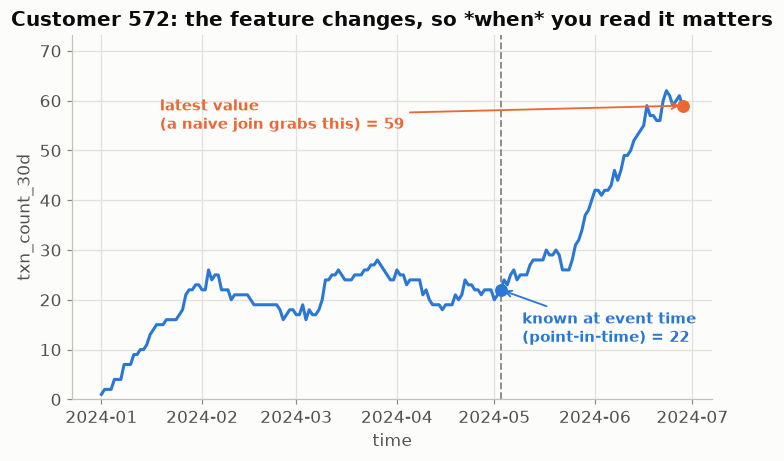

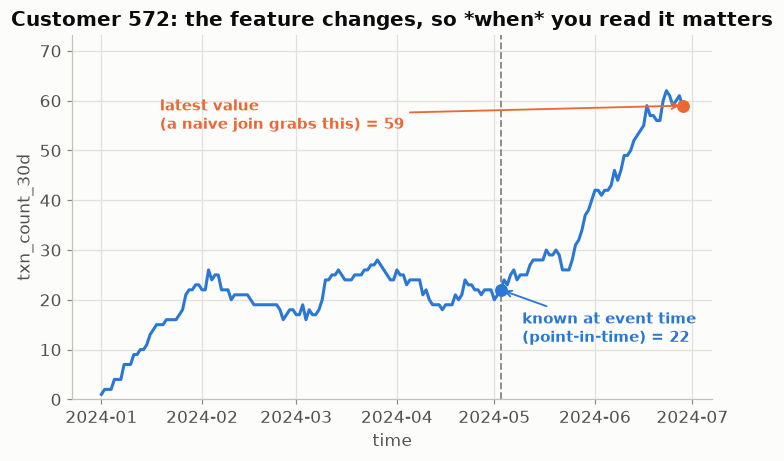

In [4]:
# Pick the positive-label customer whose latest value most overstates the point-in-time value.
offline = ds.events[~ds.events["is_future"]].copy()
latest_per_cust = (
    ds.feature_history.sort_values(EVENT_TS_COL).groupby(ENTITY_COL)[FEATURE_COL].last()
)
offline = offline.assign(latest=offline[ENTITY_COL].map(latest_per_cust))
offline = offline.assign(gap=offline["latest"] - offline[TRUTH_COL])
row = offline[offline[LABEL_COL] == 1].sort_values("gap", ascending=False).iloc[0]
customer = int(row[ENTITY_COL])

series = ds.feature_history[ds.feature_history[ENTITY_COL] == customer].sort_values(EVENT_TS_COL)
event_time = row[EVENT_TS_COL]
point_in_time = int(row[TRUTH_COL])
latest = int(series[FEATURE_COL].iloc[-1])

last_ts = series[EVENT_TS_COL].iloc[-1]
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(series[EVENT_TS_COL], series[FEATURE_COL], color=BLUE, lw=2)
ax.axvline(event_time, color=MUTED, ls="--", lw=1.2)
ax.scatter([event_time], [point_in_time], color=BLUE, s=55, zorder=5)
ax.scatter([last_ts], [latest], color=ORANGE, s=55, zorder=5)
ax.set_ylim(0, series[FEATURE_COL].max() * 1.18)
ax.annotate(f"latest value\n(a naive join grabs this) = {latest}",
            xy=(last_ts, latest), xytext=(series[EVENT_TS_COL].iloc[18], latest - 2),
            ha="left", va="center", color=ORANGE, fontsize=10, fontweight="bold",
            arrowprops={"arrowstyle": "->", "color": ORANGE, "lw": 1.2})
ax.annotate(f"known at event time\n(point-in-time) = {point_in_time}",
            xy=(event_time, point_in_time), textcoords="offset points", xytext=(14, -34),
            color=BLUE, fontsize=10, fontweight="bold",
            arrowprops={"arrowstyle": "->", "color": BLUE, "lw": 1.2})
ax.set_title(f"Customer {customer}: the feature changes, so *when* you read it matters")
ax.set_xlabel("time")
ax.set_ylabel("txn_count_30d")
save_figure(fig, "01_feature_over_time")
fig

The blue dot is the honest feature; the orange dot is the latest value. Joining the orange
value onto a label from the event time is **peeking at the future** — the heart of the leak
we measure in notebook 02. A feature store exists to make the blue value easy to get for
training and the latest value easy to get for serving, from *one* definition.

In [5]:
overview = {
    "thesis": "A feature store solves time and consistency, not storage.",
    "framing": "One feature definition served two ways: historically (point-in-time) and latest (online).",
    "two_problems": ["point-in-time correctness", "train/serve consistency"],
    "three_parts": {
        "offline_store": "timestamped history for correct training joins",
        "online_store": "latest-value key-value lookup for fast serving",
        "registry": "shared catalog of what each feature means",
    },
    "dataset_shapes": {
        "events": list(ds.events.shape),
        "feature_history": list(ds.feature_history.shape),
        "activity": list(ds.activity.shape),
    },
    "example_entity": {
        "customer_id": customer,
        "event_time": event_time,
        "point_in_time_value": point_in_time,
        "latest_value": latest,
        "overstatement": latest - point_in_time,
    },
}
print(save_json(overview, "01_overview"))
overview["example_entity"]

/workspaces/feature_store_101/outputs/json/01_overview.json


{'customer_id': 572,
 'event_time': Timestamp('2024-05-03 00:00:00'),
 'point_in_time_value': 22,
 'latest_value': 59,
 'overstatement': 37}

## Next

**[02 · Point-in-Time From Scratch](02_point_in_time_from_scratch.ipynb)** — we build a
training set the naive way and the correct way, train a model on each, and *measure* the
inflated offline AUC that collapses on a true-future holdout.